In [1]:
# Instala o pydeseq2 (e outras dependências caso precise no Colab)
!pip install pydeseq2 anndata

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.6/319.6 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 68.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.6/87.6 kB 7.2 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

np.random.seed(42)

n_genes = 1000
n_samples = 20

# 1. Criando matriz de contagem base (inteiros via Poisson)
counts = np.random.poisson(lam=50, size=(n_samples, n_genes))

# 2. SIMULANDO A DIFERENÇA BIOLÓGICA
# Vamos pegar as amostras do grupo "Tratado" (índices 10 a 19)
# Genes 0 a 50 -> Ficam Superexpressos (mais ativos no tratado)
counts[10:, 0:50] = np.random.poisson(lam=250, size=(10, 50))

# Genes 50 a 100 -> Ficam Subexpressos (menos ativos no tratado)
counts[10:, 50:100] = np.random.poisson(lam=10, size=(10, 50))

# 3. Formatando como DataFrame e inserindo nomes para os genes e amostras
counts_df = pd.DataFrame(counts, columns=[f"gene_{i}" for i in range(n_genes)])
counts_df.index = [f"amostra_{i}" for i in range(n_samples)]

# 4. Criando metadados (10 amostras controle, 10 tratadas)
conditions = ["control"] * 10 + ["treated"] * 10
metadata = pd.DataFrame({"condition": conditions})
metadata.index = counts_df.index

print("Visão geral da matriz de contagens:")
display(counts_df.head())

Visão geral da matriz de contagens:


,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,gene_9,...,gene_990,gene_991,gene_992,gene_993,gene_994,gene_995,gene_996,gene_997,gene_998,gene_999
amostra_0,47,55,42,52,58,43,46,49,52,45,...,48,60,42,53,47,48,54,47,54,50
amostra_1,48,42,56,45,46,52,68,48,51,51,...,59,50,40,36,46,42,40,40,61,57
amostra_2,38,44,42,61,60,45,47,51,54,46,...,50,46,55,53,55,59,45,50,47,39
amostra_3,43,44,56,52,50,51,50,57,41,63,...,40,52,61,39,50,47,53,50,67,50
amostra_4,51,47,38,45,51,37,53,49,51,46,...,39,60,61,45,60,51,51,57,61,56


In [3]:
# Criando o objeto DeseqDataSet combinando dados e metadados
dds = DeseqDataSet(
    counts=counts_df,
    metadata=metadata,
    design_factors="condition", # Variável alvo da análise
    n_cpus=4                    # Use mais cpus se seu ambiente permitir
)

# Executando a normalização e modelagem do DESeq2
dds.deseq2()

# Computando as estatísticas do contraste (Tratado vs Controle)
stat_res = DeseqStats(dds, contrast=["condition", "treated", "control"], n_cpus=4)
stat_res.summary()

# Extraindo os resultados limpos e removendo valores nulos
df_results = stat_res.results_df.dropna()

print("\nTabela final de resultados da expressão diferencial:")
display(df_results.head())

Using None as control genes, passed at DeseqDataSet initialization


/tmp/ipykernel_6698/131894541.py:2: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(
Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 1.61 seconds.

Fitting dispersion trend curve...
/usr/local/lib/python3.12/dist-packages/pydeseq2/dds.py:822: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.10 seconds.

Fitting MAP dispersions...
... done in 2.62 seconds.

Fitting LFCs...
... done in 1.17 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: condition treated vs control
            baseMean  log2FoldChange     lfcSE       stat         pvalue  \
gene_0    151.395215        2.525826  0.084618  29.849740  8.847110e-196   
gene_1    152.479271        2.369023  0.084187  28.140071  3.170086e-174   
gene_2    147.633482        2.390782  0.084293  28.362679  5.839623e-177   
gene_3    150.153908        2.264203  0.081633  27.736355  2.545567e-169   
gene_4    148.425723        2.227278  0.084258  26.434070  5.563370e-154   
...              ...             ...       ...        ...            ...   
gene_995   49.308271        0.049660  0.104747   0.474092   6.354344e-01   
gene_996   50.163924        0.029097  0.102555   0.283724   7.766218e-01   
gene_997   51.251653       -0.066596  0.103788  -0.641648   5.211015e-01   
gene_998   54.185288       -0.070672  0.101321  -0.697501   4.854895e-01   
gene_999   48.075936       -0.047556  0.105653  -0.450114   6.526281e-01   

                   p

... done in 0.56 seconds.



,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_0,151.395215,2.525826,0.084618,29.849740,8.847110e-196,8.847110e-193
gene_1,152.479271,2.369023,0.084187,28.140071,3.170086e-174,1.810321e-172
gene_2,147.633482,2.390782,0.084293,28.362679,5.839623e-177,4.866352e-175
gene_3,150.153908,2.264203,0.081633,27.736355,2.545567e-169,9.790641e-168
gene_4,148.425723,2.227278,0.084258,26.434070,5.563370e-154,1.112674e-152


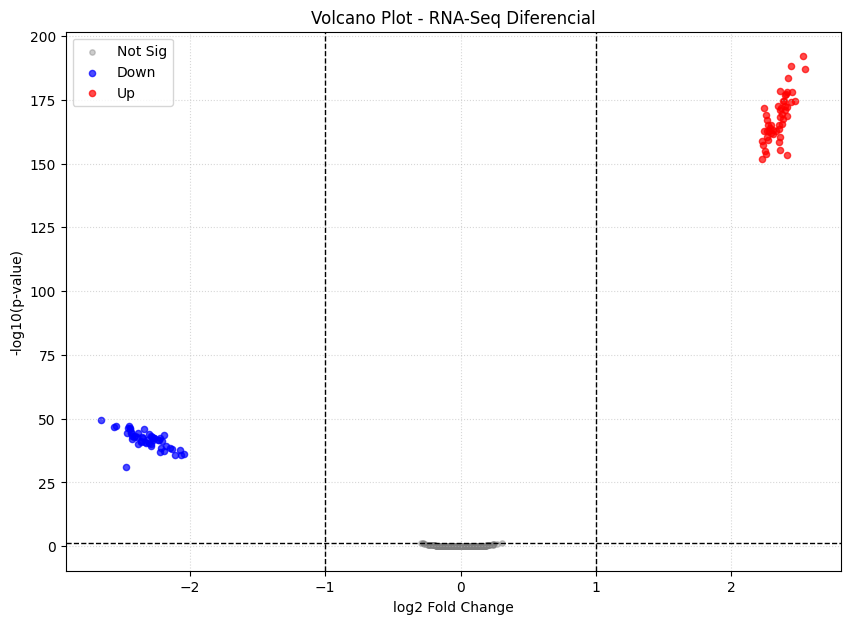

In [4]:
# Preparando a figura para o Volcano Plot
plt.figure(figsize=(10, 7))

# Definindo limiares para considerar um gene "Estatisticamente Significativo"
limiar_pvalor = 0.05
limiar_log2fc = 1.0

# Categorizando os genes baseado no p-valor ajustado e no Fold Change
sig_up = (df_results["padj"] < limiar_pvalor) & (df_results["log2FoldChange"] > limiar_log2fc)
sig_down = (df_results["padj"] < limiar_pvalor) & (df_results["log2FoldChange"] < -limiar_log2fc)
not_sig = ~sig_up & ~sig_down

# Criando o gráfico de dispersão (scatter plot)
# Genes não significativos em cinza
plt.scatter(df_results["log2FoldChange"][not_sig], -np.log10(df_results["padj"])[not_sig], color='grey', alpha=0.4, label='Not Sig', s=15)

# Genes subexpressos (esquerda) em azul
plt.scatter(df_results["log2FoldChange"][sig_down], -np.log10(df_results["padj"])[sig_down], color='blue', alpha=0.7, label='Down', s=20)

# Genes superexpressos (direita) em vermelho
plt.scatter(df_results["log2FoldChange"][sig_up], -np.log10(df_results["padj"])[sig_up], color='red', alpha=0.7, label='Up', s=20)

# Inserindo as linhas de corte para facilitar a interpretação
plt.axvline(-limiar_log2fc, color='black', linestyle='--', linewidth=1)
plt.axvline(limiar_log2fc, color='black', linestyle='--', linewidth=1)
plt.axhline(-np.log10(limiar_pvalor), color='black', linestyle='--', linewidth=1)

# Estilizando o gráfico
plt.xlabel("log2 Fold Change")
plt.ylabel("-log10(p-value)")
plt.title("Volcano Plot - RNA-Seq Diferencial")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)

plt.show()